# 03 - Layer 3 Blind Spot Analysis and Model Evolution Design

It audits what the current rule-based approach misses and lays out a practical model evolution plan for Rawasi once real closed-deal data starts arriving.

1. **Task 3A** - identify at least three blind spots, with data evidence, why rules miss them, and how the proposed model addresses them.
2. **Task 3B** - design a retraining and monitoring framework covering retraining triggers, cold start, silent degradation, and sector-specific data volume.


## 1. Setup

In [1]:
from pathlib import Path
import sys

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

pd.set_option('display.max_columns', 160)
pd.set_option('display.max_rows', 120)
pd.set_option('display.float_format', lambda x: f'{x:,.4f}')

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / 'reports').exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

REPORTS_DIR = PROJECT_ROOT / 'reports'
DATE_COLS = ['invoice_date', 'expected_payment_date', 'actual_resolution_date']

print('Project root:', PROJECT_ROOT)
print('Python:', sys.executable)

Project root: /Users/adi/Documents/ai_credit_intelligence
Python: /usr/local/bin/python3


In [2]:
def load_report(name, parse_dates=None):
    path = REPORTS_DIR / name
    if not path.exists():
        raise FileNotFoundError(f'Missing report: {path}')
    return pd.read_csv(path, parse_dates=parse_dates)


def rate_table(df, group_cols, target='defaulted', row_id='transaction_id'):
    out = (
        df.groupby(group_cols, dropna=False)
        .agg(rows=(row_id, 'size'), defaults=(target, 'sum'), default_rate=(target, 'mean'))
        .reset_index()
        .sort_values(['default_rate', 'rows'], ascending=[False, False])
    )
    return out


def quintile_table(df, feature, target='defaulted', q=5):
    temp = df[[feature, target, 'transaction_id']].dropna(subset=[feature, target]).copy()
    temp['quintile'] = pd.qcut(temp[feature].rank(method='first'), q=q, labels=[f'Q{i}' for i in range(1, q + 1)])
    return (
        temp.groupby('quintile', observed=True)
        .agg(
            rows=('transaction_id', 'size'),
            defaults=(target, 'sum'),
            default_rate=(target, 'mean'),
            avg_feature=(feature, 'mean'),
            min_feature=(feature, 'min'),
            max_feature=(feature, 'max'),
        )
        .reset_index()
    )


def bar_label_percent(ax, values):
    for i, value in enumerate(values):
        ax.text(i, value, f'{value:.1%}', ha='center', va='bottom', fontsize=9)

## 2. Load Layer Outputs

In [3]:
stage_a = load_report('stage_a_scored_transactions.csv', parse_dates=DATE_COLS)
layer1 = load_report('layer1_validation_predictions.csv', parse_dates=['invoice_date'])
stage_c = load_report('stage_c_validation_predictions.csv', parse_dates=['invoice_date'])
stage_c_metrics = load_report('stage_c_metrics.csv')
threshold_analysis = load_report('stage_c_threshold_analysis.csv')
feature_importance = load_report('stage_c_feature_importance.csv')
shap_importance = load_report('stage_c_shap_feature_importance.csv')
shap_explanations = load_report('stage_c_validation_shap_explanations.csv', parse_dates=['invoice_date'])
monitoring = load_report('layer2_scored_monitoring_frame.csv', parse_dates=DATE_COLS)
clusters = load_report('layer2_trend_clusters.csv')
drift = load_report('layer2_distribution_shift.csv')
anomalies = load_report('layer2_transaction_anomalies.csv', parse_dates=['invoice_date'])

summary = pd.DataFrame({
    'artifact': [
        'stage_a_scored_transactions', 'layer1_validation_predictions', 'stage_c_validation_predictions',
        'stage_c_shap_feature_importance', 'stage_c_validation_shap_explanations',
        'layer2_scored_monitoring_frame', 'layer2_trend_clusters', 'layer2_distribution_shift',
        'layer2_transaction_anomalies'
    ],
    'rows': [len(stage_a), len(layer1), len(stage_c), len(shap_importance), len(shap_explanations), len(monitoring), len(clusters), len(drift), len(anomalies)],
    'columns': [stage_a.shape[1], layer1.shape[1], stage_c.shape[1], shap_importance.shape[1], shap_explanations.shape[1], monitoring.shape[1], clusters.shape[1], drift.shape[1], anomalies.shape[1]],
})
summary


,artifact,rows,columns
0,stage_a_scored_transactions,5000,58
1,layer1_validation_predictions,573,16
2,stage_c_validation_predictions,431,13
3,stage_c_shap_feature_importance,194,5
4,stage_c_validation_shap_explanations,431,10
5,layer2_scored_monitoring_frame,3732,262
6,layer2_trend_clusters,605,24
7,layer2_distribution_shift,41,10
8,layer2_transaction_anomalies,684,22


## 3. Current Rule/Model Snapshot

This section establishes the baseline we are auditing. In this project, the current rule-based layer is represented by Stage A hard filters and the original scorecard-style thinking: fixed policy cuts, single-variable thresholds, and no portfolio-drift memory.


In [4]:
route_summary = (
    layer1.groupby('layer1_route', dropna=False)
    .agg(
        rows=('transaction_id', 'size'),
        defaults=('defaulted', 'sum'),
        default_rate=('defaulted', 'mean'),
        flagged_rows=('layer1_flagged_for_review', 'sum'),
    )
    .reset_index()
)
route_summary['row_share'] = route_summary['rows'] / len(layer1)
route_summary

,layer1_route,rows,defaults,default_rate,flagged_rows,row_share
0,Pass Layer 1,323,1,0.0031,0,0.5637
1,Stage A reject,142,6,0.0423,142,0.2478
2,Stage C high-risk review,108,13,0.1204,108,0.1885


In [5]:
metrics_display = pd.concat([
    load_report('layer1_validation_metrics.csv').assign(model_scope='Layer 1 full validation'),
    stage_c_metrics.assign(model_scope='Stage C only')
], ignore_index=True)
metrics_display

,scope,rows,defaults,flagged_rows,flagged_rate,precision,recall,true_negatives,false_positives,false_negatives,true_positives,model_scope,split,default_rate,auc_pr,auc_roc,ks,brier_score,threshold,predicted_positive_rate
0,full_layer1_validation,573,20,250.0000,0.4363,0.0760,0.9500,322,231,1,19,Layer 1 full validation,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,3048,130,NaN,NaN,0.2820,1.0000,2587,331,0,130,Stage C only,train,0.0427,0.7246,0.9839,0.9151,0.0623,0.4000,0.1512
2,NaN,431,14,NaN,NaN,0.1204,0.9286,322,95,1,13,Stage C only,validation,0.0325,0.6517,0.9296,0.7055,0.1180,0.4000,0.2506


### Stage C SHAP Snapshot

These SHAP outputs show which engineered features most influence validation predictions and provide deal-level drivers for analyst review.


In [6]:
display(shap_importance.head(20))

shap_cols = [
    'transaction_id', 'invoice_date', 'defaulted', 'stage_c_default_probability',
    'stage_c_predicted_default', 'stage_c_top_positive_shap_reasons',
    'stage_c_top_negative_shap_reasons'
]
display(shap_explanations.sort_values('stage_c_default_probability', ascending=False)[shap_cols].head(10))


,feature,mean_abs_shap,mean_shap,gain,gain_share
0,log_cumulative_outstanding_usd,0.5402,-0.1205,248.3374,0.0375
1,stage_b_exp_debt_to_equity_peer_z,0.3805,-0.1698,79.2273,0.0120
2,stage_b_benchmark_score,0.2221,-0.1489,50.3401,0.0076
3,stage_b_log_cumulative_outstanding_usd_risk_pe...,0.1778,-0.0402,230.4127,0.0348
4,stage_b_exposure_quality_pressure_peer_z,0.1262,0.0178,120.9321,0.0183
5,stage_b_concentration_adjusted_total_exposure_...,0.1064,-0.0428,32.7089,0.0049
6,ticket_to_revenue_est,0.1057,-0.0076,53.6052,0.0081
7,stage_b_exp_leverage_liquidity_stress_peer_z,0.1026,-0.0567,30.9843,0.0047
8,stage_b_uninsured_funded_amount_usd_peer_z,0.1006,-0.0459,63.3028,0.0096
9,stage_b_funded_amount_usd_peer_z,0.0926,-0.0403,29.3836,0.0044


,transaction_id,invoice_date,defaulted,stage_c_default_probability,stage_c_predicted_default,stage_c_top_positive_shap_reasons,stage_c_top_negative_shap_reasons
14,TX-004618,2025-10-04,1,0.9806,1,log_cumulative_outstanding_usd=17.32 (+2.3615)...,stage_b_total_exposure_tenor_to_revenue_days_p...
127,TX-001804,2025-10-28,1,0.9766,1,log_cumulative_outstanding_usd=17.11 (+2.0907)...,stage_b_exp_fx_loss_x_tenor_peer_z=-0.941 (-0....
120,TX-000034,2025-10-26,1,0.9653,1,log_cumulative_outstanding_usd=17.1 (+2.2916);...,stage_b_total_exposure_tenor_to_revenue_days_p...
22,TX-000764,2025-10-05,1,0.9635,1,log_cumulative_outstanding_usd=17.11 (+1.9432)...,stage_b_concentration_adjusted_total_exposure_...
50,TX-002879,2025-10-10,1,0.9520,1,log_cumulative_outstanding_usd=17.13 (+2.0258)...,buyer_terms_pressure=0.08395 (-0.0973); stage_...
0,TX-004630,2025-10-01,1,0.9447,1,log_cumulative_outstanding_usd=16.81 (+1.6282)...,stage_b_concentration_adjusted_total_exposure_...
33,TX-001860,2025-10-07,1,0.9210,1,log_cumulative_outstanding_usd=17.33 (+1.9718)...,stage_b_benchmark_score=58.71 (-0.5888); buyer...
165,TX-000617,2025-11-08,0,0.9126,1,log_cumulative_outstanding_usd=16.7 (+1.6292);...,exp_young_firm_risk=0.05263 (-0.1675); stage_b...
48,TX-002237,2025-10-09,1,0.9082,1,log_cumulative_outstanding_usd=16.69 (+1.0534)...,stage_b_exp_historical_on_time_gap_peer_z=-0.6...
47,TX-004129,2025-10-09,0,0.9046,1,stage_b_exp_debt_to_equity_peer_z=3.561 (+0.44...,ticket_to_revenue_est=0.6768 (-0.0549); stage_...


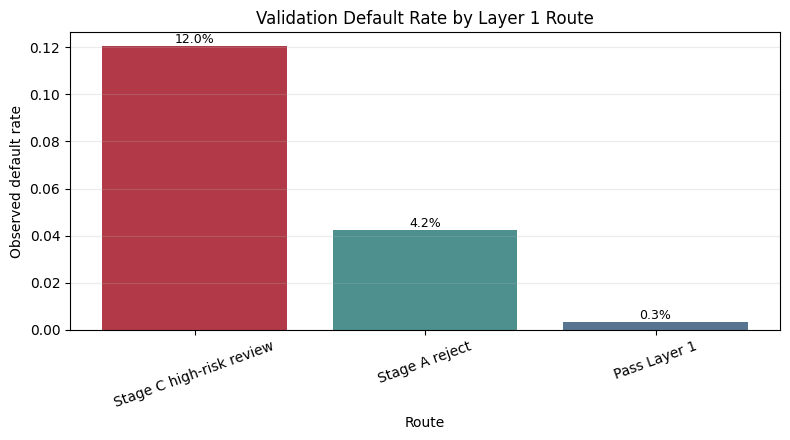

In [7]:
fig, ax = plt.subplots(figsize=(8, 4.5))
route_plot = route_summary.sort_values('default_rate', ascending=False)
ax.bar(route_plot['layer1_route'], route_plot['default_rate'], color=['#b23a48', '#4d908e', '#577590'])
bar_label_percent(ax, route_plot['default_rate'])
ax.set_title('Validation Default Rate by Layer 1 Route')
ax.set_ylabel('Observed default rate')
ax.set_xlabel('Route')
ax.tick_params(axis='x', rotation=20)
ax.grid(axis='y', alpha=0.25)
plt.tight_layout()

## 4. Task 3A - Blind Spot 1: Rules Do Not Understand Exposure Relative to Exporter Capacity

**Name:** Exposure overextension and concentration risk.

**Why this is a blind spot:** A fixed rule can reject obvious policy failures, but it does not understand whether a deal is large relative to the exporter revenue base, whether Rawasi is already overexposed to the exporter, or whether the new funded amount pushes the client into concentration stress.

**How the model addresses it:** Stage B derives `outstanding_to_revenue_est`, `total_exposure_to_revenue_est`, `exposure_quality_pressure`, and related peer outlier features. Stage C then learns non-linear cutoffs instead of using one absolute invoice-size threshold.


In [8]:
validation_passed = monitoring[(monitoring['stage_b_split'].eq('validation')) & monitoring['defaulted'].notna()].copy()
exposure_features = [
    'outstanding_to_revenue_est',
    'total_exposure_to_revenue_est',
    'exposure_quality_pressure',
    'stage_b_benchmark_score',
    'stage_c_default_probability',
]

exposure_quintiles = {feature: quintile_table(validation_passed, feature) for feature in exposure_features}
exposure_quintiles['total_exposure_to_revenue_est']

,quintile,rows,defaults,default_rate,avg_feature,min_feature,max_feature
0,Q1,87,0.0000,0.0000,1.9658,0.4532,3.4740
1,Q2,86,0.0000,0.0000,5.1879,3.5222,7.1693
2,Q3,86,0.0000,0.0000,10.0222,7.2335,13.1475
3,Q4,86,6.0000,0.0698,19.2960,13.2081,27.0174
4,Q5,86,8.0000,0.0930,51.7418,28.0620,158.4993


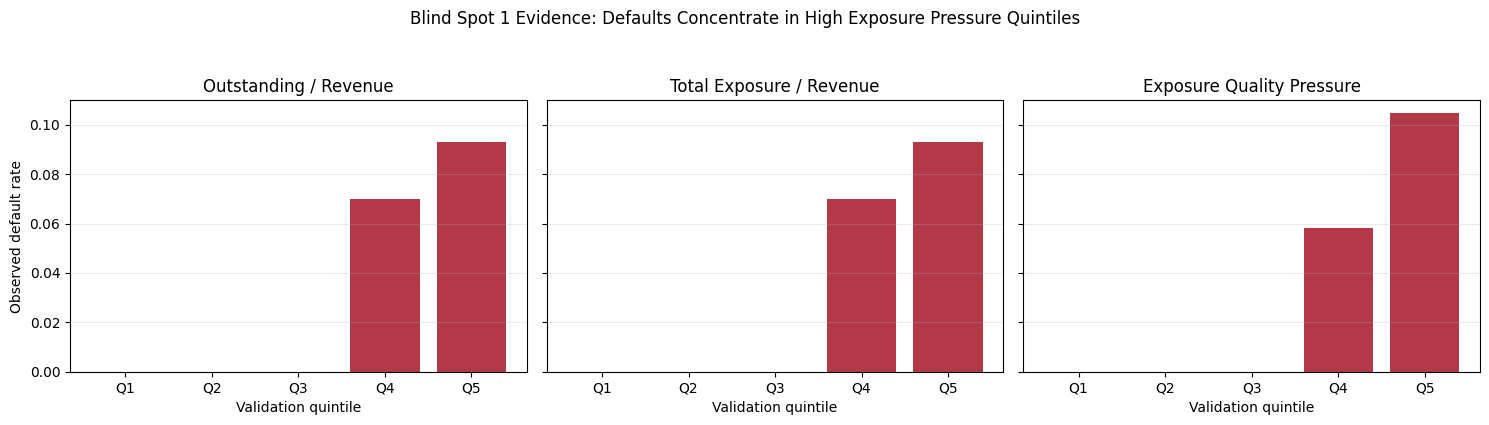

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, feature, title in zip(
    axes,
    ['outstanding_to_revenue_est', 'total_exposure_to_revenue_est', 'exposure_quality_pressure'],
    ['Outstanding / Revenue', 'Total Exposure / Revenue', 'Exposure Quality Pressure'],
):
    tab = exposure_quintiles[feature]
    ax.bar(tab['quintile'].astype(str), tab['default_rate'], color='#b23a48')
    ax.set_title(title)
    ax.set_xlabel('Validation quintile')
    ax.grid(axis='y', alpha=0.25)
axes[0].set_ylabel('Observed default rate')
plt.suptitle('Blind Spot 1 Evidence: Defaults Concentrate in High Exposure Pressure Quintiles', y=1.05)
plt.tight_layout()

**Interpretation:** In the validation set, the lower exposure quintiles have near-zero observed defaults, while defaults concentrate in the highest exposure-pressure quintiles. A banker-built rulebook using only buyer country, documentation, or simple credit grade would not capture this relative exposure effect.


## 5. Task 3A - Blind Spot 2: Hard Filters Are Too Blunt and Over-Reject Paid Deals

**Name:** Binary policy thresholds create high false-positive review/reject volume.

**Why this is a blind spot:** Rules such as buyer-country ceilings or CreditSafe floors treat all breaches equally. They cannot rank risk within a breached segment or recognize when a deal has compensating strengths.

**How the model addresses it:** Stage B/C keep risk as continuous evidence. The model can still route high-risk cases for review, but the review queue is based on combined probability, peer outliers, exposure pressure, and benchmark score rather than one isolated rule.


In [10]:
stage_a_validation = layer1[layer1['stage_a_decision'].eq('REJECT_STAGE_A')].copy()
stage_a_reject_summary = (
    stage_a_validation.groupby('stage_a_reject_reasons', dropna=False)
    .agg(rows=('transaction_id', 'size'), defaults=('defaulted', 'sum'), default_rate=('defaulted', 'mean'))
    .reset_index()
    .sort_values(['rows', 'default_rate'], ascending=[False, False])
)
stage_a_reject_summary['paid_or_nondefault_rows'] = stage_a_reject_summary['rows'] - stage_a_reject_summary['defaults']
stage_a_reject_summary.head(12)

,stage_a_reject_reasons,rows,defaults,default_rate,paid_or_nondefault_rows
1,Buyer country risk score above 8,70,2,0.0286,68
4,Exporter historical dispute rate at or above 8%,29,1,0.0345,28
5,Missing mandatory documentation,26,2,0.0769,24
7,Missing mandatory documentation; Buyer country...,7,0,0.0000,7
0,Buyer CreditSafe rating is E,3,0,0.0000,3
2,Buyer country risk score above 8; Buyer Credit...,3,0,0.0000,3
8,Missing mandatory documentation; Exporter hist...,2,0,0.0000,2
3,Buyer country risk score above 8; Exporter his...,1,1,1.0000,0
6,Missing mandatory documentation; Buyer CreditS...,1,0,0.0000,1


In [11]:
layer1_confusion = pd.DataFrame({
    'group': ['Layer 1 reviewed/rejected', 'Layer 1 passed'],
    'rows': [int(layer1['layer1_flagged_for_review'].sum()), int((~layer1['layer1_flagged_for_review'].astype(bool)).sum())],
    'defaults': [int(layer1.loc[layer1['layer1_flagged_for_review'].astype(bool), 'defaulted'].sum()), int(layer1.loc[~layer1['layer1_flagged_for_review'].astype(bool), 'defaulted'].sum())],
})
layer1_confusion['default_rate'] = layer1_confusion['defaults'] / layer1_confusion['rows']
layer1_confusion['nondefaults'] = layer1_confusion['rows'] - layer1_confusion['defaults']
layer1_confusion

,group,rows,defaults,default_rate,nondefaults
0,Layer 1 reviewed/rejected,250,19,0.0760,231
1,Layer 1 passed,323,1,0.0031,322


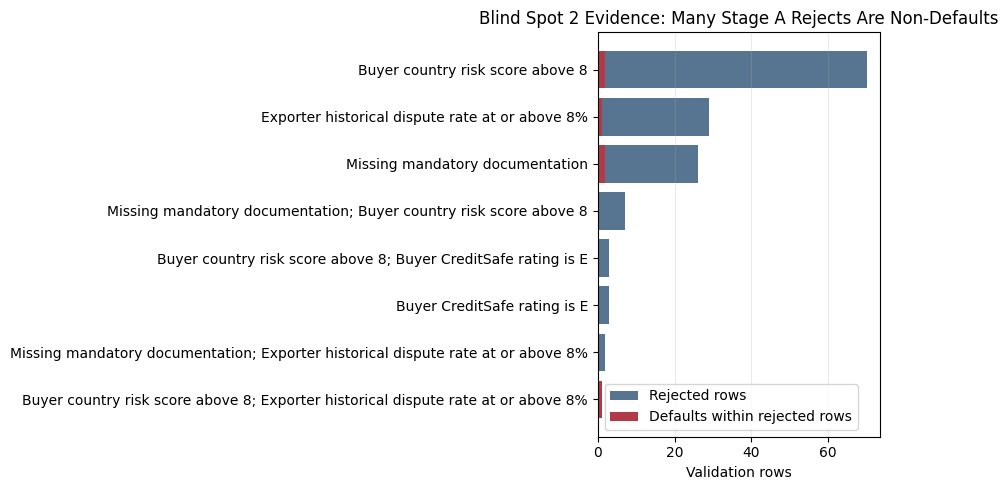

In [12]:
fig, ax = plt.subplots(figsize=(9, 5))
plot_df = stage_a_reject_summary.head(8).sort_values('rows')
ax.barh(plot_df['stage_a_reject_reasons'].astype(str), plot_df['rows'], color='#577590', label='Rejected rows')
ax.barh(plot_df['stage_a_reject_reasons'].astype(str), plot_df['defaults'], color='#b23a48', label='Defaults within rejected rows')
ax.set_title('Blind Spot 2 Evidence: Many Stage A Rejects Are Non-Defaults')
ax.set_xlabel('Validation rows')
ax.legend()
ax.grid(axis='x', alpha=0.25)
plt.tight_layout()

**Interpretation:** Stage A intentionally catches policy problems, but as a credit-risk model it is blunt. In validation, Stage A rejects include many paid/non-default deals. That is acceptable for non-negotiable documentation policy, but it is weak as a risk-ranking system. The evolution design should keep hard filters only for true policy/data-quality gates and move risk-sensitive variables into Stage B/C.


## 6. Task 3A - Blind Spot 3: Rules Miss Multi-Variable Interactions and Emerging Segment Drift

**Name:** Static rules cannot detect combinations that become risky over time.

**Why this is a blind spot:** A rule may know that a buyer country or goods category is acceptable in isolation, but it does not track whether a specific country/category, country/currency, or sector/goods combination is suddenly worsening in a recent window.

**How the model addresses it:** Layer 2 adds trend monitoring and PSI drift. It does not automatically reject deals; it creates early-warning alerts for human review and model retraining decisions.


In [13]:
alert_clusters = clusters[clusters['alert_flag']].copy()
cluster_evidence_cols = [
    'cluster_definition', 'cluster_key', 'recent_rows', 'recent_defaults', 'recent_default_rate',
    'train_rows', 'train_defaults', 'train_default_rate', 'default_rate_lift',
    'recent_avg_predicted_probability', 'model_underestimated_recent_risk'
]
alert_clusters[cluster_evidence_cols].sort_values(['recent_default_rate', 'default_rate_lift'], ascending=False).head(15)

,cluster_definition,cluster_key,recent_rows,recent_defaults,recent_default_rate,train_rows,train_defaults,train_default_rate,default_rate_lift,recent_avg_predicted_probability,model_underestimated_recent_risk
0,buy_buyer_country + goods_category,Iraq / Metals,6,3,0.5000,17,0,0.0000,11.8125,0.5936,False
230,buy_buyer_country + exp_segment,Italy / LC,6,2,0.3333,68,4,0.0588,2.7083,0.2292,True
266,buy_buyer_sector + goods_category,Agriculture - Agri Processing / Textiles,8,2,0.2500,16,0,0.0000,7.2222,0.2940,False
1,buy_buyer_country + goods_category,Spain / Food,5,1,0.2000,32,0,0.0000,8.4000,0.2255,False
267,buy_buyer_sector + goods_category,Printing and Packaging / Agricultural,5,1,0.2000,18,0,0.0000,5.6000,0.2572,False
2,buy_buyer_country + goods_category,Kenya / Chemicals,5,1,0.2000,25,1,0.0400,2.3333,0.7245,False
3,buy_buyer_country + goods_category,Germany / Textiles,6,1,0.1667,41,0,0.0000,9.5625,0.3199,False
430,exp_industry + goods_category,Textiles - Apparel Manufacturing / Textiles,6,1,0.1667,27,0,0.0000,6.9375,0.3982,False
431,exp_industry + goods_category,Fertilizer / Chemicals,6,1,0.1667,23,0,0.0000,6.1875,0.4647,False
268,buy_buyer_sector + goods_category,Textiles - Fabric Manufacturing / Metals,6,1,0.1667,21,0,0.0000,5.8125,0.3743,False


In [14]:
significant_drift = drift[drift['human_review_required']].copy()
significant_drift[['feature', 'psi', 'severity', 'baseline_mean', 'incoming_mean']].head(10)

,feature,psi,severity,baseline_mean,incoming_mean
0,log_cumulative_outstanding_usd,0.7954,significant_shift,13.8109,15.5466
1,log_outstanding_to_revenue_est,0.4707,significant_shift,1.7495,2.3599
2,outstanding_to_revenue_est,0.4707,significant_shift,10.7898,16.9563
3,total_exposure_to_revenue_est,0.3613,significant_shift,11.5229,17.6064
4,exposure_quality_pressure,0.3534,significant_shift,24.2495,36.7366


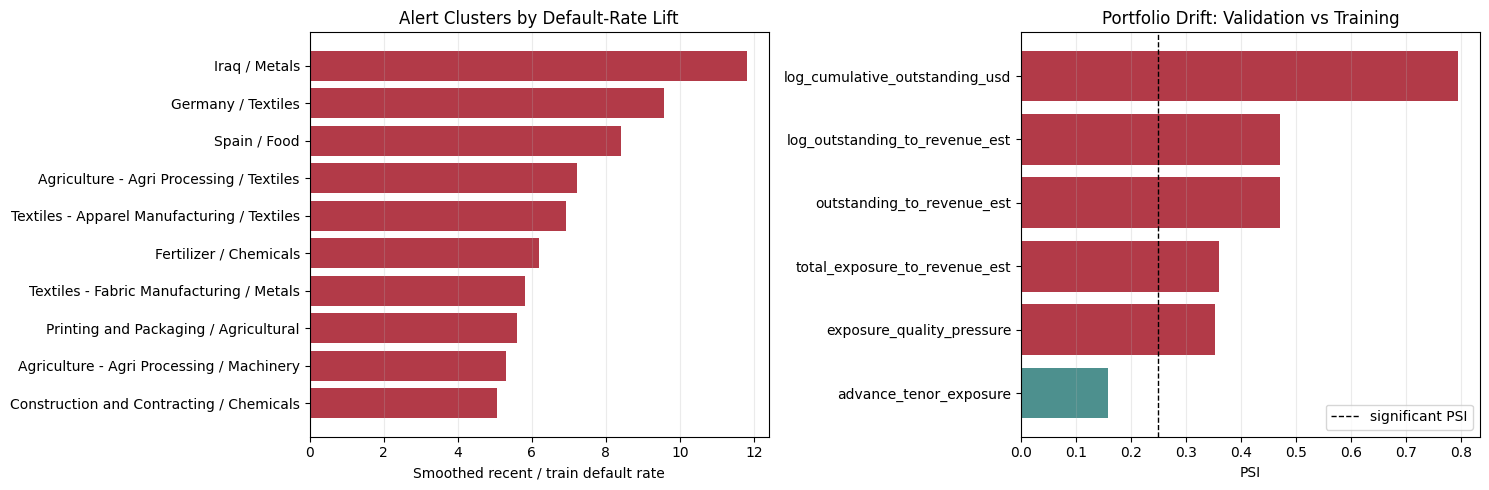

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

cluster_plot = alert_clusters.sort_values('default_rate_lift').tail(10)
axes[0].barh(cluster_plot['cluster_key'], cluster_plot['default_rate_lift'], color='#b23a48')
axes[0].set_title('Alert Clusters by Default-Rate Lift')
axes[0].set_xlabel('Smoothed recent / train default rate')
axes[0].grid(axis='x', alpha=0.25)

psi_plot = drift.sort_values('psi').tail(10)
colors = np.where(psi_plot['human_review_required'], '#b23a48', '#4d908e')
axes[1].barh(psi_plot['feature'], psi_plot['psi'], color=colors)
axes[1].axvline(0.25, color='black', linestyle='--', linewidth=1, label='significant PSI')
axes[1].set_title('Portfolio Drift: Validation vs Training')
axes[1].set_xlabel('PSI')
axes[1].legend()
axes[1].grid(axis='x', alpha=0.25)

plt.tight_layout()

**Interpretation:** This is the clearest Layer 3 blind spot: the rules are static, but the validation population has shifted materially toward higher exposure pressure. The alert clusters are small-sample early warnings, so they should trigger monitoring and investigation rather than automatic rejection.


## 7. Task 3A - Blind Spot 4: The Current Model Still Misses Some Default Patterns

The proposed system is better than a static rulebook, but it is not perfect. A credible Layer 3 audit should also name what the new model misses.

**Name:** Medium-score defaults that look acceptable globally but are locally unusual.

**Why this matters:** The model is recall-first and still has one validation false negative. This deal passed Stage A and Stage C, despite multiple peer outlier reasons.

**How to address it with more time:** Add local peer-neighborhood anomaly features into the operating threshold, use conformal/outlier flags as override-to-review rules, and collect more real defaults for calibration.


In [16]:
false_negatives = layer1[(layer1['defaulted'].eq(1)) & (~layer1['layer1_flagged_for_review'].astype(bool))].copy()
false_negatives

,transaction_id,invoice_date,status,defaulted,stage_a_decision,stage_a_reject_reasons,stage_b_benchmark_score,stage_b_benchmark_band,stage_b_peer_outlier_count,stage_c_default_probability,stage_c_predicted_default,stage_c_top_positive_shap_reasons,stage_c_top_negative_shap_reasons,stage_c_shap_margin,layer1_flagged_for_review,layer1_route
365,TX-003019,2025-11-07,defaulted,1,PASS_STAGE_A,NaN,50.0500,Medium,7.0000,0.2513,0,log_cumulative_outstanding_usd=16.83 (+1.3746)...,stage_b_benchmark_score=50.05 (-0.6493); stage...,-1.0914,0,Pass Layer 1


In [17]:
if false_negatives.empty:
    display(Markdown('No Layer 1 false negatives in validation.'))
else:
    fn_ids = false_negatives['transaction_id'].tolist()
    fn_detail_cols = [
        'transaction_id', 'invoice_date', 'status', 'defaulted', 'buy_buyer_country', 'goods_category',
        'invoice_currency', 'stage_c_default_probability', 'stage_c_predicted_default',
        'stage_b_benchmark_score', 'stage_b_benchmark_band', 'stage_b_peer_high_risk_outlier_count',
        'stage_b_peer_outlier_score', 'total_exposure_to_revenue_est', 'buyer_dso_to_terms',
        'exposure_quality_pressure', 'stage_b_peer_outlier_reasons'
    ]
    display(monitoring.loc[monitoring['transaction_id'].isin(fn_ids), fn_detail_cols])

,transaction_id,invoice_date,status,defaulted,buy_buyer_country,goods_category,invoice_currency,stage_c_default_probability,stage_c_predicted_default,stage_b_benchmark_score,stage_b_benchmark_band,stage_b_peer_high_risk_outlier_count,stage_b_peer_outlier_score,total_exposure_to_revenue_est,buyer_dso_to_terms,exposure_quality_pressure,stage_b_peer_outlier_reasons
3316,TX-003019,2025-11-07,defaulted,1.0000,Italy,Chemicals,AED,0.2513,0,50.0500,Medium,7,100.0000,22.6661,1.9355,39.3484,outstanding_to_revenue_est high vs goods_categ...


## 8. Task 3B - Model Evolution Design

### 8.1 Retraining Triggers

Retrain the champion model when one of these conditions is met:

| Trigger | Concrete threshold | Reason |
|---|---:|---|
| New resolved data volume | At least 500 new resolved deals and at least 25 new defaults since last training | Avoid retraining on mostly unlabeled/noisy data |
| Performance degradation | Validation or rolling AUC-PR falls by 15% from champion baseline, or recall at the operating threshold falls below 85% | Rawasi is default-sensitive; false negatives are expensive |
| Calibration drift | Top risk decile observed default rate differs from predicted rate by more than 2x over two consecutive monitoring windows | Pricing and review capacity depend on calibrated risk |
| Population drift | Any core feature PSI above 0.25, or three or more features above 0.10 for two consecutive windows | Indicates the book is changing versus training data |
| Segment failure | Any segment with at least 50 resolved deals has recall below 75% or default rate 2x portfolio average | Protects against silent local failures |
| External shock | Currency crisis, inflation shock, buyer-country downgrade, or sector disruption | Risk regime can change before labels arrive |

Default cadence: monitor weekly, review monthly, retrain quarterly if triggers and data volume are sufficient.


### 8.2 Cold Start Plan

Cold start occurs when a new exporter, buyer, country/goods combination, or goods category has little or no repayment history.

Design response:

1. Use the sector-agnostic Stage B benchmark as the default baseline.
2. Apply hierarchical fallback: exact peer group -> goods category -> buyer country -> global portfolio.
3. Smooth all segment rates with priors so small segments do not dominate decisions.
4. Use external and decision-time signals first: buyer country risk, CreditSafe, DSO, insurance, invoice tenor, exposure/revenue, concentration, and documentation quality.
5. Cap exposure for cold-start entities until enough repayment history is observed.
6. Route cold-start high-exposure deals to human review even when model probability is moderate.


### 8.3 Silent Degradation Controls

To prevent silent degradation as market conditions change:

- Maintain a champion/challenger setup. The current XGBoost model remains champion; challengers are trained on newer windows and compared out of time.
- Monitor AUC-PR, recall, precision, Brier score, calibration by decile, PSI, and false-negative segments weekly.
- Keep a fixed holdout period that is never used for fitting or threshold selection.
- Add market-context features as they become available: inflation, FX movement, policy-rate changes, country downgrade events, and commodity/sector stress indicators.
- Use Layer 2 alerts as model-governance signals, not just dashboard output.
- Require credit committee signoff before changing the operating threshold or Stage A hard policy rules.


### 8.4 Minimum Data Volume for Sector-Specific Scoring

Do not trust a sector-specific score until the sector has enough resolved outcomes to estimate default risk with tolerable variance.

Recommended minimum before moving from sector-agnostic to sector-specific scoring:

| Requirement | Minimum |
|---|---:|
| Resolved deals in sector | 300 |
| Defaults in sector | 30 |
| Distinct exporters | 50 |
| Distinct buyers | 50 |
| Time coverage | At least 2 full business cycles or 6 months of live operations, whichever is longer |
| Stability check | Sector PSI below 0.25 versus its own recent baseline |

Until these thresholds are met, use the sector-agnostic model with sector-level monitoring overlays and conservative exposure caps.
